Loaded dataset: C:\Users\ASUS\Downloads\archive (10)\Genre Classification Dataset\test_data_solution.txt

Dataset shape: (54087, 4)

Genre distribution:
GENRE
drama          13565
documentary    13086
comedy          7437
short           5061
horror          2204
thriller        1589
action          1314
western         1030
reality-tv       881
family           774
adventure        773
music            720
romance          670
sci-fi           645
adult            590
crime            505
animation        498
sport            430
talk-show        389
fantasy          322
mystery          318
musical          273
biography        264
history          243
game-show        193
news             181
war              132
Name: count, dtype: int64

Training records: 43269
Testing records: 10818

Training model...
Training completed!

========== MODEL EVALUATION ==========
Accuracy: 51.04%

Classification Report:
              precision    recall  f1-score   support

      action       0.30  

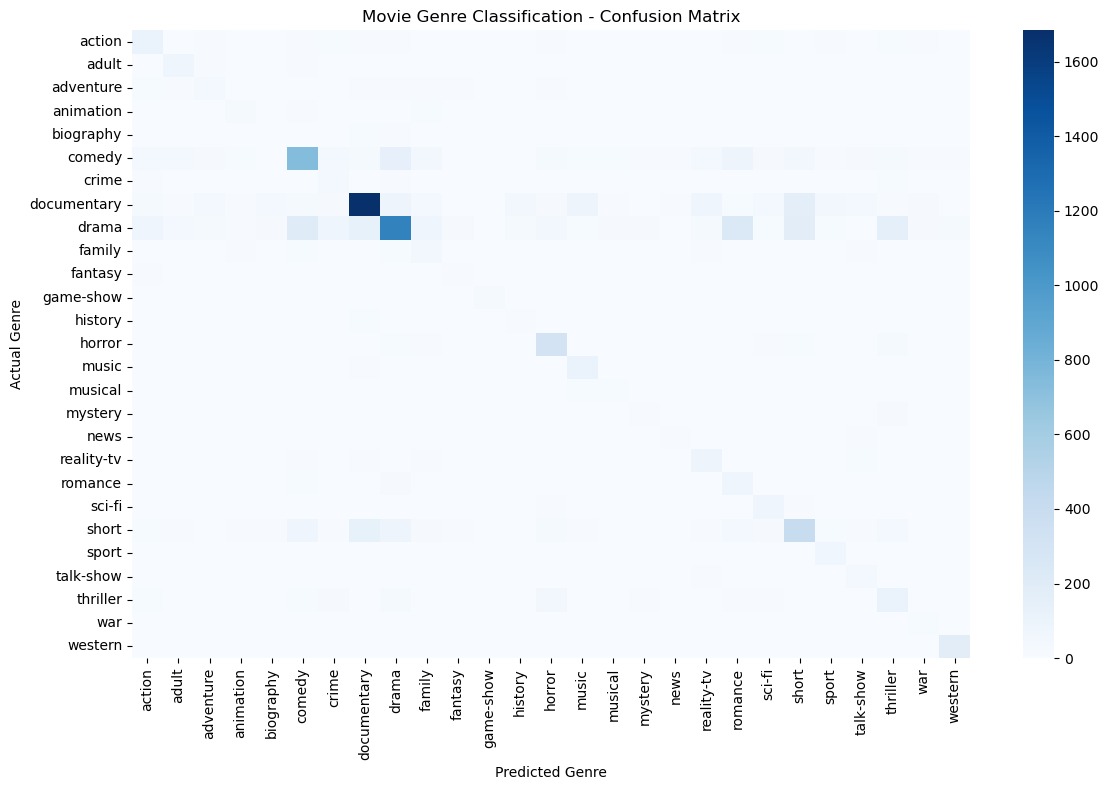


Movie Plot: 
A brave detective investigates a mysterious murder and follows
clues to find the criminal responsible for the crime.

Predicted Genre: crime

Top 3 predicted genres:
crime: 52.52%
mystery: 40.41%
thriller: 3.80%

Model saved at: C:\Users\ASUS\Downloads\archive (10)\Genre Classification Dataset\movie_genre_model.pkl

Movie Plot: 
A young man falls in love with a woman, but family problems
and misunderstandings make their relationship difficult.

Predicted Genre: romance

Top 3 predicted genres:
romance: 42.04%
drama: 30.94%
comedy: 5.71%


In [2]:

import os
import glob
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")

# 1. Dataset path
DATASET_PATH = r"C:\Users\ASUS\Downloads\archive (10)\Genre Classification Dataset"

if not os.path.isdir(DATASET_PATH):
    raise FileNotFoundError("Dataset folder not found. Check your path.")

# 2. Find the dataset file
txt_files = glob.glob(os.path.join(DATASET_PATH, "**", "*.txt"), recursive=True)
csv_files = glob.glob(os.path.join(DATASET_PATH, "**", "*.csv"), recursive=True)

df = None

# Load standard Kaggle Genre Classification Dataset
for file in txt_files:
    try:
        temp = pd.read_csv(
            file, sep=r"\s*:::\s*", engine="python",
            header=None, on_bad_lines="skip"
        )
        if temp.shape[1] >= 4:
            df = temp.iloc[:, :4].copy()
            df.columns = ["ID", "TITLE", "GENRE", "DESCRIPTION"]
            print("Loaded dataset:", file)
            break
    except Exception:
        pass

# If no suitable TXT file exists, try CSV
if df is None:
    for file in csv_files:
        try:
            temp = pd.read_csv(file)
            cols = {re.sub(r"[^a-z0-9]", "", str(c).lower()): c
                    for c in temp.columns}

            genre_col = next(
                (cols[k] for k in ["genre", "genres", "moviegenre", "label", "target"]
                 if k in cols), None
            )
            text_col = next(
                (cols[k] for k in ["description", "plot", "plotsummary",
                                    "summary", "overview", "text", "synopsis"]
                 if k in cols), None
            )
            title_col = next(
                (cols[k] for k in ["title", "movietitle", "name"]
                 if k in cols), None
            )

            if genre_col and text_col:
                df = pd.DataFrame()
                df["GENRE"] = temp[genre_col]
                df["DESCRIPTION"] = temp[text_col].fillna("").astype(str)
                if title_col:
                    df["DESCRIPTION"] = (
                        temp[title_col].fillna("").astype(str) + " " +
                        df["DESCRIPTION"]
                    )
                print("Loaded dataset:", file)
                break
        except Exception:
            pass

if df is None:
    raise ValueError(
        "No compatible dataset found. The folder must contain a standard "
        "train_data.txt file or a CSV with genre and plot/description columns."
    )

# 3. Clean data
df["GENRE"] = df["GENRE"].astype(str).str.strip()
df["DESCRIPTION"] = df["DESCRIPTION"].fillna("").astype(str).str.strip()

df = df[
    df["GENRE"].ne("") &
    df["GENRE"].str.lower().ne("nan") &
    df["DESCRIPTION"].ne("")
].drop_duplicates(subset=["GENRE", "DESCRIPTION"])

print("\nDataset shape:", df.shape)
print("\nGenre distribution:")
print(df["GENRE"].value_counts())

if df["GENRE"].nunique() < 2:
    raise ValueError("The dataset must contain at least two genres.")

X = df["DESCRIPTION"]
y = df["GENRE"]

# 4. Split data into training and testing sets
stratify_labels = y if y.value_counts().min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42,
    stratify=stratify_labels
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# 5. Build and train model
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        max_features=50000,
        ngram_range=(1, 2),
        min_df=1,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

print("\nTraining model...")
model.fit(X_train, y_train)
print("Training completed!")

# 6. Evaluate model
y_pred = model.predict(X_test)

print("\n========== MODEL EVALUATION ==========")
print(f"Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# 7. Plot confusion matrix
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)

plt.figure(figsize=(12, 8))
sns.heatmap(cm, cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title("Movie Genre Classification - Confusion Matrix")
plt.xlabel("Predicted Genre")
plt.ylabel("Actual Genre")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 8. Predict genre for a new movie plot
def predict_genre(plot):
    prediction = model.predict([plot])[0]
    print("\nMovie Plot:", plot)
    print("Predicted Genre:", prediction)

    probabilities = model.predict_proba([plot])[0]
    classes = model.named_steps["classifier"].classes_
    top = np.argsort(probabilities)[::-1][:3]

    print("\nTop 3 predicted genres:")
    for i in top:
        print(f"{classes[i]}: {probabilities[i] * 100:.2f}%")

# Example prediction
sample_plot = """
A brave detective investigates a mysterious murder and follows
clues to find the criminal responsible for the crime.
"""
predict_genre(sample_plot)

# 9. Save trained model
model_path = os.path.join(DATASET_PATH, "movie_genre_model.pkl")
joblib.dump(model, model_path)
print("\nModel saved at:", model_path)

# 10. Try another movie plot
new_plot = """
A young man falls in love with a woman, but family problems
and misunderstandings make their relationship difficult.
"""
predict_genre(new_plot)
